# 03 — Merged Development Dataset Inspection and Class Imbalance (IEEE-CIS Fraud Detection)

**Project:** Fraud Detection Under Limited Review Capacity: A Temporally Validated Study of Gradient-Boosting Models and Decision Policies
**Programme / module:** MSc Data Science, University of Greenwich — COMP1885 Individual Project
**GitHub Issue:** #44
**Notebook status:** data-understanding evidence. No model is trained and no file is written. All outputs are aggregates.

## Purpose

[Notebook 02](02_raw_table_schema_inventory.ipynb) inspected the two raw tables separately. This notebook inspects the **merged (joined) dataset** that later preparation will build ([DR-008](../docs/decisions/DR-008-feature-declaration-and-model-input-policy.md)):

1. join validity on keys only;
2. the merged development dataset: shape, column roles and data types (dtypes);
3. **class imbalance** of the target `isFraud` (1 = fraud, 0 = legitimate), with bar charts;
4. identity coverage, and fraud prevalence (share of transactions that are fraud) with and without identity information;
5. missingness by feature group after the merge.

## Test-sealing rule

The file name `train_transaction.csv` is the competition organiser's name for the labelled file. It contains **all 182 relative days**, including this study's **sealed Test period** (relative days 155–182, [DR-001](../docs/decisions/DR-001-temporal-split-strategy.md)). A relative day is `TransactionDT` (time offset in seconds from an undisclosed reference point) divided by 86,400 seconds and rounded down.

Counting frauds over the whole file would reveal the Test fraud count by subtraction. Therefore:

- Section 2 uses **keys only** (`TransactionID`, `TransactionDT`): no label and no feature value.
- Every statistic from Section 3 onwards uses **development rows only** (relative days 1–154: Train, Validation 1 and Validation 2). Rows are sorted by time (notebook 01 §3), so only the first 511,998 transaction rows are read, and the day-154 boundary is asserted.
- The Test period appears only as its row count (78,542).

Evidence tags: **[D]** observed dataset evidence; **[I]** inference or recommendation.

## 1. Setup

In [1]:
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
TX_PATH = RAW / "train_transaction.csv"
ID_PATH = RAW / "train_identity.csv"
FEATURES_PATH = ROOT / "config" / "features.yaml"

KEY = "TransactionID"
TARGET = "isFraud"
TIME = "TransactionDT"
SECONDS_PER_DAY = 86_400

# Chronological partitions by relative day and their row counts (DR-001).
PARTITIONS = {"Train": (1, 105), "V1": (106, 126), "V2": (127, 154), "Test": (155, 182)}
DEV_PARTITIONS = ["Train", "V1", "V2"]
EXPECTED_PARTITION_ROWS = {"Train": 368_632, "V1": 65_544, "V2": 77_822, "Test": 78_542}
DEV_ROWS = sum(EXPECTED_PARTITION_ROWS[p] for p in DEV_PARTITIONS)   # 511,998
TEST_ROWS = EXPECTED_PARTITION_ROWS["Test"]                          # 78,542
TOTAL_ROWS = DEV_ROWS + TEST_ROWS                                    # 590,540
LAST_DEV_DAY = PARTITIONS["V2"][1]                                   # 154
JOINED_COLUMNS = 434

# Chart colours: validated categorical pair (legitimate = slot 1, fraud = slot 2) plus neutral ink.
COLOR = {"legitimate": "#2a78d6", "fraud": "#eb6834", "sealed": "#c3c2b7",
         "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COLOR["ink2"], "axes.labelcolor": COLOR["ink"], "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True,
    "axes.grid.axis": "y", "grid.color": COLOR["grid"], "grid.linewidth": 0.8,
    "xtick.color": COLOR["ink2"], "ytick.color": COLOR["ink2"], "font.size": 9.5,
    "legend.frameon": False,
})


def relative_day(transaction_dt):
    """Relative day = floor(TransactionDT / 86,400); no calendar date is inferred."""
    return transaction_dt // SECONDS_PER_DAY


def partition_of(day):
    for name, (first, last) in PARTITIONS.items():
        if first <= day <= last:
            return name
    raise ValueError(f"Relative day {day} lies outside DR-001 partitions")


def feature_group(col):
    """Organiser feature group of a column (names only)."""
    if col == KEY:
        return "Key"
    if col == TARGET:
        return "Target"
    if col == TIME:
        return "Time"
    if col == "TransactionAmt":
        return "Amount"
    if col == "ProductCD":
        return "Product"
    if col.startswith("card"):
        return "Card"
    if col in ("addr1", "addr2"):
        return "Address"
    if col in ("dist1", "dist2"):
        return "Distance"
    if col.endswith("emaildomain"):
        return "Email domain"
    if col[0] == "C" and col[1:].isdigit():
        return "C (counts)"
    if col[0] == "D" and col[1:].isdigit():
        return "D (time deltas)"
    if col[0] == "M" and col[1:].isdigit():
        return "M (match flags)"
    if col[0] == "V" and col[1:].isdigit():
        return "V (organiser-engineered)"
    if col.startswith("id_"):
        return "Identity id_01-id_38"
    if col in ("DeviceType", "DeviceInfo"):
        return "Device"
    return "Other"


GROUP_ORDER = ["Key", "Target", "Time", "Amount", "Product", "Card", "Address", "Distance",
               "Email domain", "C (counts)", "D (time deltas)", "M (match flags)",
               "V (organiser-engineered)", "Identity id_01-id_38", "Device", "Other"]

print("Python", sys.version.split()[0], "|", platform.platform())
for module in (pd, np, matplotlib, yaml):
    print(f"{module.__name__:<11}{module.__version__}")
print("Repository root:", ROOT)

Python 3.12.3 | Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
pandas     3.0.6
numpy      2.5.3
matplotlib 3.11.2
yaml       6.0.3
Repository root: /home/chathuranga/projects/fraud-detection-review-capacity


## 2. Join validity (keys only; label-free)

The merge is a **left join**: every transaction row is kept, and identity columns are attached where an identity record exists. Only the key columns are read here.

In [2]:
tx_keys = pd.read_csv(TX_PATH, usecols=[KEY, TIME])
id_keys = pd.read_csv(ID_PATH, usecols=[KEY])

assert tx_keys[KEY].is_unique and id_keys[KEY].is_unique
assert tx_keys[TIME].is_monotonic_increasing, "Rows are not sorted by TransactionDT"
assert id_keys[KEY].isin(tx_keys[KEY]).all(), "Identity rows without a matching transaction"

probe = tx_keys[[KEY]].merge(id_keys, on=KEY, how="left", validate="one_to_one")
assert len(probe) == TOTAL_ROWS

days = relative_day(tx_keys[TIME])
assert int((days <= LAST_DEV_DAY).sum()) == DEV_ROWS
assert days.iloc[DEV_ROWS - 1] <= LAST_DEV_DAY < days.iloc[DEV_ROWS], "Day-154 boundary is not at row 511,998"
partition_rows = days.map(partition_of).value_counts().reindex(list(PARTITIONS))
assert partition_rows.to_dict() == EXPECTED_PARTITION_ROWS

pd.DataFrame({
    "check": [
        "Transaction rows (all 182 days)",
        "Identity rows, all matched to a transaction",
        "Rows after left join (one-to-one, row-preserving)",
        "Development rows (days 1-154) = first rows of the file",
        "Test rows (days 155-182) - sealed",
    ],
    "value": [len(tx_keys), len(id_keys), len(probe), DEV_ROWS, TEST_ROWS],
})

,check,value
0,Transaction rows (all 182 days),590540
1,"Identity rows, all matched to a transaction",144233
2,"Rows after left join (one-to-one, row-preserving)",590540
3,Development rows (days 1-154) = first rows of ...,511998
4,Test rows (days 155-182) - sealed,78542


## 3. Merged development dataset

Only the first 511,998 transaction rows are read (`nrows`), so no Test-period row — and therefore no Test label — is loaded. The identity table has no label and is read in full, then left-joined.

`relative_day`, `partition` and `has_identity` are kept in a **separate metadata frame**. They describe rows for this inspection and are not model inputs.

In [3]:
tx_dev = pd.read_csv(TX_PATH, nrows=DEV_ROWS)
assert len(tx_dev) == DEV_ROWS
assert relative_day(tx_dev[TIME]).max() <= LAST_DEV_DAY, "A Test-period row was read"

identity = pd.read_csv(ID_PATH)
merged = tx_dev.merge(identity, on=KEY, how="left", validate="one_to_one")
assert merged.shape == (DEV_ROWS, JOINED_COLUMNS), merged.shape

meta = pd.DataFrame({
    "relative_day": relative_day(merged[TIME]),
    "has_identity": merged[KEY].isin(identity[KEY]),
})
meta["partition"] = meta["relative_day"].map(partition_of)
assert set(meta["partition"]) == set(DEV_PARTITIONS)
assert set(merged[TARGET].unique()) <= {0, 1} and merged[TARGET].notna().all()

features = yaml.safe_load(FEATURES_PATH.read_text())
roles = {
    "target": [features["target"]],
    "excluded": [entry["name"] for entry in features["excluded"]],
    "categorical": features["categorical"]["transaction"] + features["categorical"]["identity"],
    "numeric": features["numeric"]["columns"],
}
assert sorted(c for cols in roles.values() for c in cols) == sorted(merged.columns)

display(pd.DataFrame({
    "item": ["Rows (development)", "Columns (merged)", "Target", "Excluded identifiers",
             "Categorical model inputs", "Numeric model inputs"],
    "value": [merged.shape[0], merged.shape[1], len(roles["target"]), len(roles["excluded"]),
              len(roles["categorical"]), len(roles["numeric"])],
}))
merged.dtypes.astype(str).value_counts().rename("columns").to_frame()

,item,value
0,Rows (development),511998
1,Columns (merged),434
2,Target,1
3,Excluded identifiers,2
4,Categorical model inputs,49
5,Numeric model inputs,382


,columns
float64,399
str,31
int64,4


## 4. Class imbalance (development data)

For a set of transactions, the fraud prevalence and the imbalance ratio are:

$$
\begin{aligned}
\pi &= \frac{n_{\mathrm{pos}}}{n} \\
\mathrm{IR} &= \frac{n_{\mathrm{neg}}}{n_{\mathrm{pos}}}
\end{aligned}
$$

where:

- `π` = fraud prevalence (share of transactions with `isFraud` = 1);
- `IR` = imbalance ratio (legitimate transactions per fraud);
- `n` = number of transactions; `n_pos` = number of frauds; `n_neg` = number of legitimate transactions.

### 4.1 Counts, prevalence and imbalance ratio by partition

In [4]:
rows = []
for part in DEV_PARTITIONS + ["Development (Train + V1 + V2)"]:
    mask = meta["partition"].isin(DEV_PARTITIONS) if part.startswith("Development") else meta["partition"] == part
    n = int(mask.sum())
    n_pos = int(merged.loc[mask, TARGET].sum())
    rows.append({"partition": part, "rows": n, "legitimate": n - n_pos, "fraud": n_pos,
                 "prevalence %": round(100 * n_pos / n, 3),
                 "imbalance ratio (legitimate : fraud)": f"{(n - n_pos) / n_pos:.1f} : 1"})
rows.append({"partition": "Test (sealed)", "rows": TEST_ROWS, "legitimate": "not computed",
             "fraud": "not computed", "prevalence %": np.nan,
             "imbalance ratio (legitimate : fraud)": "sealed"})
imbalance = pd.DataFrame(rows)
assert imbalance.loc[imbalance["partition"].isin(DEV_PARTITIONS), "rows"].tolist() == \
    [EXPECTED_PARTITION_ROWS[p] for p in DEV_PARTITIONS]
imbalance

,partition,rows,legitimate,fraud,prevalence %,imbalance ratio (legitimate : fraud)
0,Train,368632,356148,12484,3.387,28.5 : 1
1,V1,65544,62776,2768,4.223,22.7 : 1
2,V2,77822,75185,2637,3.389,28.5 : 1
3,Development (Train + V1 + V2),511998,494109,17889,3.494,27.6 : 1
4,Test (sealed),78542,not computed,not computed,NaN,sealed


### 4.2 Bar charts

- **Left:** legitimate versus fraud counts over all development rows, on a linear axis so the imbalance is shown at its true scale.
- **Right:** fraud prevalence by partition. The Test bar is a hatched placeholder: its labels are sealed, so no prevalence is computed or shown.

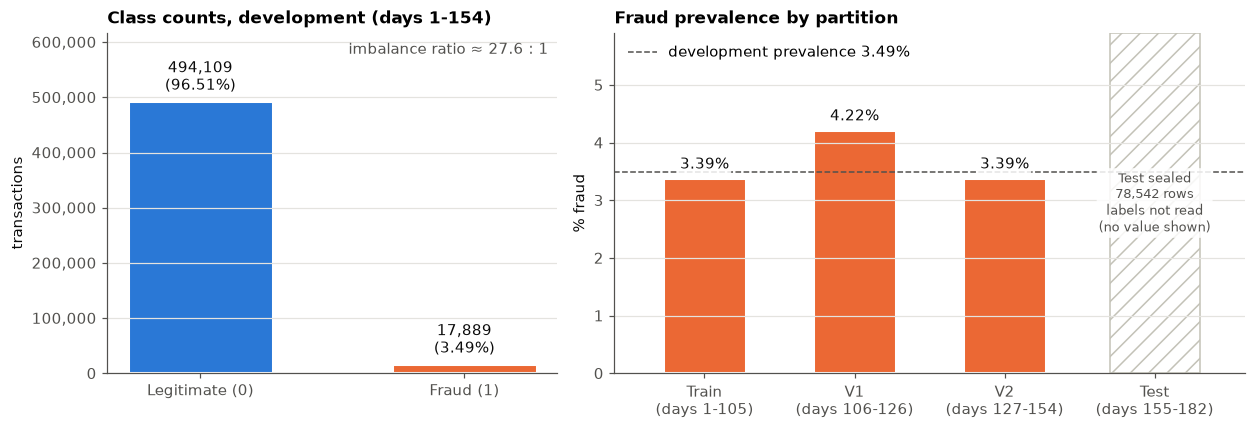

In [5]:
dev = imbalance.set_index("partition").loc["Development (Train + V1 + V2)"]
dev_prev = dev["fraud"] / dev["rows"]
label_box = {"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.85}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"width_ratios": [1, 1.4]})

# Left: class counts, development data (linear axis = true scale of the imbalance).
classes = ["Legitimate (0)", "Fraud (1)"]
counts = [dev["legitimate"], dev["fraud"]]
bars = ax1.bar(classes, counts, color=[COLOR["legitimate"], COLOR["fraud"]], width=0.55,
               edgecolor="white", linewidth=2)
for bar, value in zip(bars, counts):
    ax1.annotate(f"{value:,}\n({100 * value / dev['rows']:.2f}%)",
                 (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4),
                 textcoords="offset points", ha="center", va="bottom", color=COLOR["ink"])
ax1.set_ylim(0, max(counts) * 1.25)
ax1.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax1.set_ylabel("transactions")
ax1.set_title(f"Class counts, development (days 1-{LAST_DEV_DAY})")
ax1.text(0.98, 0.97, f"imbalance ratio ≈ {dev['legitimate'] / dev['fraud']:.1f} : 1",
         transform=ax1.transAxes, ha="right", va="top", color=COLOR["ink2"])

# Right: prevalence by partition; Test is a hatched band with no value.
dev_parts = imbalance.set_index("partition").loc[DEV_PARTITIONS]
prev = 100 * dev_parts["fraud"].astype(float) / dev_parts["rows"].astype(float)
x = np.arange(len(DEV_PARTITIONS) + 1)
top = prev.max() * 1.4
ax2.bar(x[:-1], prev, color=COLOR["fraud"], width=0.55, edgecolor="white", linewidth=2)
for xi, value in zip(x[:-1], prev):
    ax2.annotate(f"{value:.2f}%", (xi, value), xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", color=COLOR["ink"], bbox=label_box)
ax2.axvspan(x[-1] - 0.3, x[-1] + 0.3, ymin=0, ymax=1, facecolor="none",
            edgecolor=COLOR["sealed"], hatch="//", linewidth=1)
ax2.text(x[-1], top / 2, f"Test sealed\n{TEST_ROWS:,} rows\nlabels not read\n(no value shown)",
         ha="center", va="center", color=COLOR["ink2"], fontsize=8.5, bbox=label_box)
ax2.axhline(100 * dev_prev, color=COLOR["ink2"], linestyle="--", linewidth=1,
            label=f"development prevalence {100 * dev_prev:.2f}%")
ax2.set_xticks(x, [f"{p}\n(days {PARTITIONS[p][0]}-{PARTITIONS[p][1]})" for p in DEV_PARTITIONS]
               + [f"Test\n(days {PARTITIONS['Test'][0]}-{PARTITIONS['Test'][1]})"])
ax2.set_xlim(-0.6, x[-1] + 0.6)
ax2.set_ylim(0, top)
ax2.set_ylabel("% fraud")
ax2.set_title("Fraud prevalence by partition")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 5. Identity coverage after the merge (development data)

The identity table covers only part of the transactions. After the left join, rows without an identity record carry missing values in all 40 identity columns. This section shows how coverage and fraud prevalence differ between transactions with and without identity information.

In [6]:
records = []
for part in DEV_PARTITIONS:
    m = meta["partition"] == part
    has = m & meta["has_identity"]
    lacks = m & ~meta["has_identity"]
    records.append({
        "partition": part,
        "rows": int(m.sum()),
        "identity coverage %": round(100 * has.sum() / m.sum(), 1),
        "prevalence % (identity present)": round(100 * merged.loc[has, TARGET].mean(), 2),
        "prevalence % (identity absent)": round(100 * merged.loc[lacks, TARGET].mean(), 2),
    })
pd.DataFrame(records)

,partition,rows,identity coverage %,prevalence % (identity present),prevalence % (identity absent)
0,Train,368632,27.1,6.83,2.11
1,V1,65544,20.7,12.08,2.18
2,V2,77822,17.5,9.38,2.12


## 6. Missingness by feature group after the merge (development data)

In [7]:
groups = pd.Series({c: feature_group(c) for c in merged.columns})
missing_pct = merged.isna().mean() * 100
missingness = (missing_pct.groupby(groups)
               .agg(n_columns="size", mean_missing_pct="mean", min_missing_pct="min", max_missing_pct="max")
               .reindex([g for g in GROUP_ORDER if g in groups.values])
               .round(1))
assert "Other" not in missingness.index
missingness

,n_columns,mean_missing_pct,min_missing_pct,max_missing_pct
Key,1,0.0,0.0,0.0
Target,1,0.0,0.0,0.0
Time,1,0.0,0.0,0.0
Amount,1,0.0,0.0,0.0
Product,1,0.0,0.0,0.0
Card,6,0.4,0.0,1.4
Address,2,11.2,11.2,11.2
Distance,2,76.9,60.3,93.4
Email domain,2,46.1,15.7,76.5
C (counts),14,0.0,0.0,0.0


## 7. Findings

- **[D]** The left join is one-to-one and preserves all 590,540 transaction rows; all 144,233 identity rows match a transaction. The first 511,998 rows of `train_transaction.csv` are exactly relative days 1–154.
- **[D]** The merged development dataset has 511,998 rows and 434 columns (399 `float64`, 31 text, 4 `int64`), matching the roles in `config/features.yaml`.
- **[D]** Development class balance: 494,109 legitimate and 17,889 fraud transactions — prevalence 3.494 %, imbalance ratio 27.6 : 1. This matches notebook 01 §5.
- **[D]** Prevalence by partition: Train 3.387 % (28.5 : 1), V1 4.223 % (22.7 : 1), V2 3.389 % (28.5 : 1). V1 is the high-prevalence period.
- **[D]** Identity coverage falls over time: Train 27.1 %, V1 20.7 %, V2 17.5 %. Prevalence is much higher with identity information (6.83 %, 12.08 %, 9.38 %) than without (2.11 %, 2.18 %, 2.12 %).
- **[D]** After the merge, identity columns are on average 84.6 % missing and device columns 77.7 % (rows without an identity record count as missing); D, distance and M groups are 52–77 % missing on average; key, target, time, amount, product and C columns are complete.
- **[D]** Test is represented by its row count only (78,542); no Test-period label was read.
- **[I]** The dataset is imbalanced/low-prevalence (≈ 28 : 1), not severely imbalanced, consistent with the protocol's terminology. The falling identity coverage combined with its strong association with fraud is a composition shift that can move score distributions — relevant to threshold transfer (RQ2/H3).

## Symbols and notation

| Symbol / abbreviation | Meaning |
|---|---|
| [D], [I] | Evidence tags: observed dataset evidence; inference or recommendation |
| DR-NNN | Decision Record NNN in `docs/decisions/` |
| dtype | Stored data type of a column |
| IR | Imbalance ratio: legitimate transactions per fraud, n_neg / n_pos |
| `isFraud` | Target: 1 = fraud, 0 = legitimate |
| n, n_pos, n_neg | Numbers of transactions, frauds and legitimate transactions |
| π | Fraud prevalence: n_pos / n |
| Relative day | `TransactionDT` divided by 86,400 seconds, rounded down; no calendar date inferred |
| Test | Relative days 155–182; labels sealed |
| Train, V1, V2 | Relative days 1–105; 106–126 (Validation 1); 127–154 (Validation 2) |
| `TransactionDT` | Time offset in seconds from an undisclosed reference point |
| `TransactionID` | Row identifier and join key |